# UNIVERSIDAD AUTÓNOMA DE OCCIDENTE
## FACULTAD DE INGENIERÍA
## APRENDIZAJE AUTOMÁTICO
## PROFESOR: Juan Camilo Giraldo Londoño
## Estudiantes: 

### **TAREA 1: PROBLEMAS DE REGRESIÓN**

----
**Anotaciones**
El objetivo de este proyecto es analizar los datos de un data set para un problema
de regresión y desarrollar un algoritmo de regresión lineal.


#### Dataset Utilizado: **https://archive.ics.uci.edu/dataset/242/energy+efficiency**

## 1# Realizar el Analisis Exploratorio de Datos del Dataset Energy Efficiency.

In [ ]:
# importando librerias

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
print("pandas", pd.__version__, "| seaborn", sns.__version__)

# importando dataset
# En caso de no tener instalado el paquete ucimlrepo, se puede instalar con el comando: uv add ucimlrepo 
# Si no tienen la interfaz de UV instalada y van correr esto en collab, pueden instalar el paquete descomentando la linea pip
# !pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
energy_efficiency = fetch_ucirepo(id=242)

# data (as pandas dataframes)
X = energy_efficiency.data.features
y = energy_efficiency.data.targets

# variable information
print(energy_efficiency.variables)



pandas 3.0.6 | seaborn 0.13.2
  name     role        type demographic                description units  \
0   X1  Feature  Continuous        None       Relative Compactness  None   
1   X2  Feature  Continuous        None               Surface Area  None   
2   X3  Feature  Continuous        None                  Wall Area  None   
3   X4  Feature  Continuous        None                  Roof Area  None   
4   X5  Feature  Continuous        None             Overall Height  None   
5   X6  Feature     Integer        None                Orientation  None   
6   X7  Feature  Continuous        None               Glazing Area  None   
7   X8  Feature     Integer        None  Glazing Area Distribution  None   
8   Y1   Target  Continuous        None               Heating Load  None   
9   Y2   Target  Continuous        None               Cooling Load  None   

  missing_values  
0             no  
1             no  
2             no  
3             no  
4             no  
5             no  


In [69]:
# Apariencia de tablas y gráficas
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

In [70]:
def resumen(df):
    # Ficha técnica por columna: tipo, nulos, cardinalidad y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

In [71]:
#y = energy_efficiency.data.targets["Y1"]
#print(energy_efficiency.data.targets.columns)

#E_efficiency = pd.read_csv("https://archive.ics.uci.edu/static/public/242/data.csv")
#print("Dimensiones:", E_efficiency.shape)
print("X1: Relative Compactness: X2: Surface Area X3: Wall Area X4: Roof Area X5: Overall Height X6: Orientation X7: Glazing Area X8: Glazing Area Distribution")
print("Dimensiones:", energy_efficiency.data.features.shape)
# Renombramos los datos de entrada (features) y de salida (targets) a EF_F y EF_T respectivamente
EF_F = energy_efficiency.data.features
EF_T = energy_efficiency.data.targets
EF_F.head()

X1: Relative Compactness: X2: Surface Area X3: Wall Area X4: Roof Area X5: Overall Height X6: Orientation X7: Glazing Area X8: Glazing Area Distribution
Dimensiones: (768, 8)


,X1,X2,X3,X4,X5,X6,X7,X8
0,0.980,514.500,294.000,110.250,7.000,2,0.000,0
1,0.980,514.500,294.000,110.250,7.000,3,0.000,0
2,0.980,514.500,294.000,110.250,7.000,4,0.000,0
3,0.980,514.500,294.000,110.250,7.000,5,0.000,0
4,0.900,563.500,318.500,122.500,7.000,2,0.000,0


In [72]:
resumen(EF_F)

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
X1,float64,768,0,0.000,12,0.980
X2,float64,768,0,0.000,12,514.500
X3,float64,768,0,0.000,7,294.000
X4,float64,768,0,0.000,4,110.250
X5,float64,768,0,0.000,2,7.000
X6,int64,768,0,0.000,4,2.000
X7,float64,768,0,0.000,4,0.000
X8,int64,768,0,0.000,6,0.000


#### El conjunto de datos contiene ocho atributos (o características, denotados por X1...X8) y dos respuestas (o resultados, denotados por y1 e y2). El objetivo es utilizar las ocho características para predecir cada una de las dos respuestas.
----
**En concreto:**

X1: Compacidad relativa 

X2: Área de superficie

X3: Área de pared 

X4: Área del techo 

X5: Altura total 

X6: Orientación

X7: Área de acristalamiento

X8: Distribución del área de acristalamiento

Y1: Carga de calefacción
Y2: Carga de refrigeración

In [73]:
EF_F.describe().T

,count,mean,std,min,25%,50%,75%,max
X1,768.000,0.764,0.106,0.620,0.682,0.750,0.830,0.980
X2,768.000,671.708,88.086,514.500,606.375,673.750,741.125,808.500
X3,768.000,318.500,43.626,245.000,294.000,318.500,343.000,416.500
X4,768.000,176.604,45.166,110.250,140.875,183.750,220.500,220.500
X5,768.000,5.250,1.751,3.500,3.500,5.250,7.000,7.000
X6,768.000,3.500,1.119,2.000,2.750,3.500,4.250,5.000
X7,768.000,0.234,0.133,0.000,0.100,0.250,0.400,0.400
X8,768.000,2.812,1.551,0.000,1.750,3.000,4.000,5.000


In [74]:
resumen(EF_T)

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Y1,float64,768,0,0.000,586,15.550
Y2,float64,768,0,0.000,636,21.330


Analisis de T

X2                  : máximo =       808 | aparece 64 veces (8.3%)
X3                  : máximo =       416 | aparece 64 veces (8.3%)


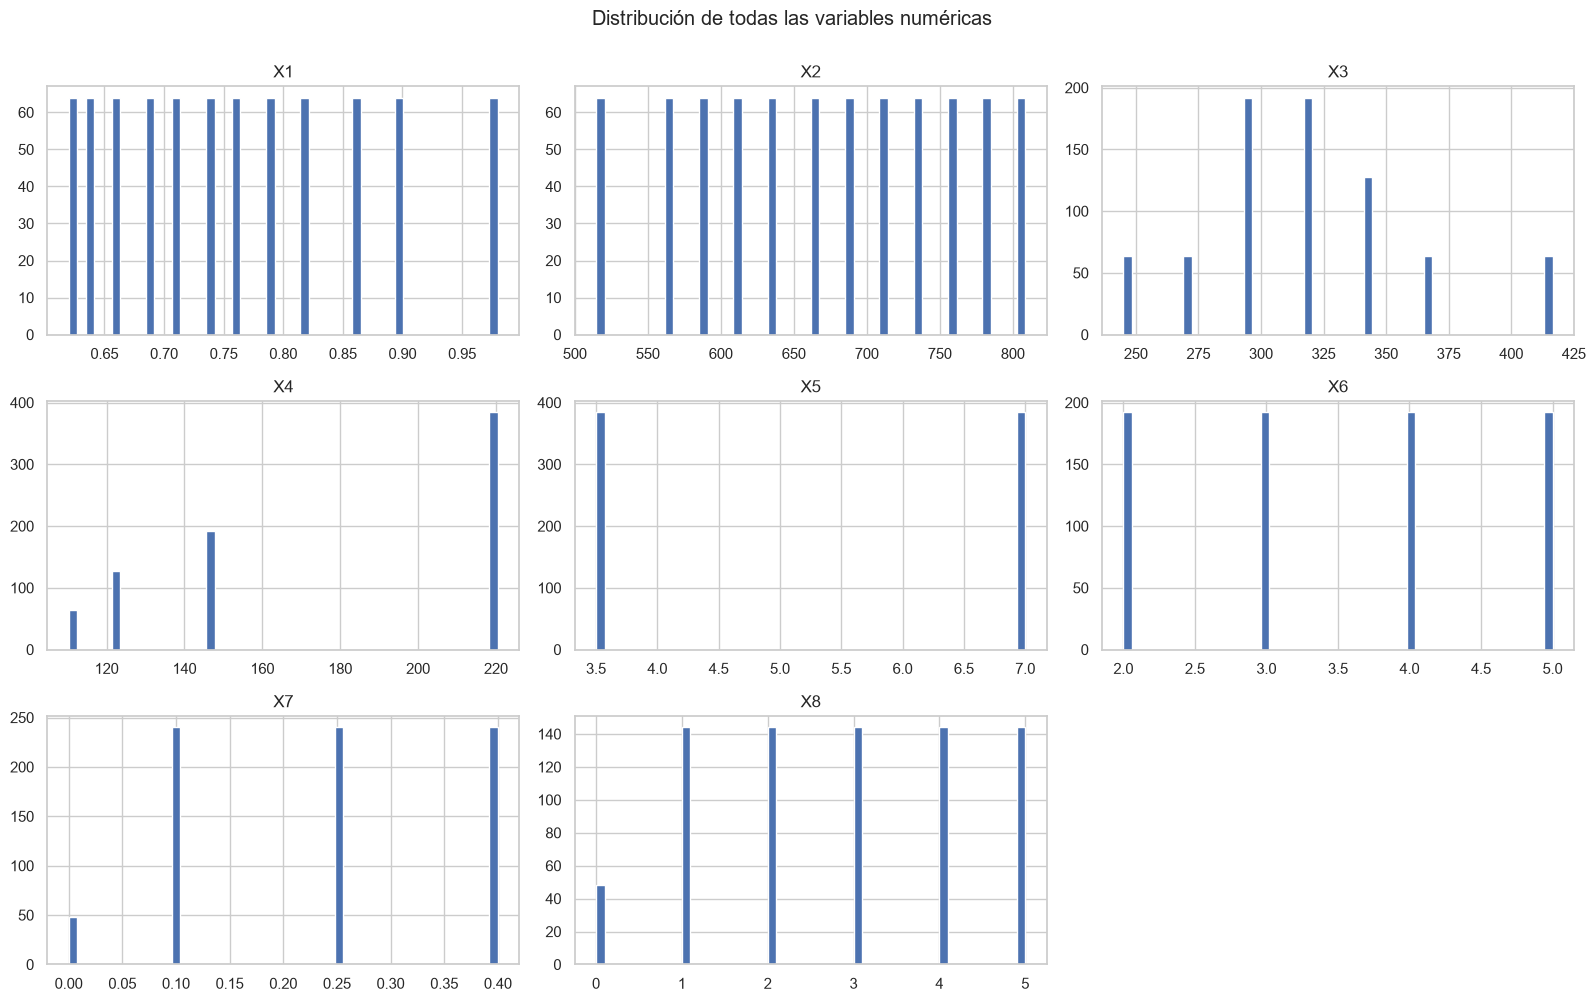

In [75]:
for col in ["X2", "X3"]:
    maximo = EF_F[col].max()
    n = (EF_F[col] == maximo).sum()
    print(f"{col:20s}: máximo = {maximo:>9,.0f} | aparece {n} veces ({n / len(EF_F):.1%})")

EF_F.hist(bins=50, figsize=(16, 10))
plt.suptitle("Distribución de todas las variables numéricas", y=1.0); plt.tight_layout(); plt.show()

# 2# Estimación de los parámetros